In [28]:
import pandas as pd

# Load both CSV files
df1 = pd.read_csv('csv/final_1.csv')
df2 = pd.read_csv('csv/final_2.csv')

# Combine them row-wise
combined_df = pd.concat([df1, df2], ignore_index=True)

# (Optional) Save the result to a new CSV
combined_df.to_csv('csv/combined_file.csv', index=False)

# Display first few rows
print(combined_df.head())


       latitude      longitude   bbox_lat_y1    bbox_lon_x1   bbox_lat_y2  \
0  3.430046e+06  607218.277016  3.430060e+06  607160.463748  3.430033e+06   
1  3.430022e+06  607214.730640  3.430035e+06  607156.728346  3.430008e+06   
2  3.429319e+06  618157.169623  3.429327e+06  618095.098755  3.429310e+06   
3  3.429348e+06  618161.864484  3.429356e+06  618099.651709  3.429339e+06   
4  3.429232e+06  618145.048096  3.429241e+06  618082.851306  3.429224e+06   

     bbox_lon_x2  bbox_width_geo  bbox_height_geo      global_x     global_y  \
0  607276.090283      115.626535        27.036841    384.423386  1535.905518   
1  607272.732935      116.004588        27.052112    372.602135  1617.795471   
2  618219.240491      124.141736        17.064844  16797.398743  4177.343140   
3  618224.077258      124.425549        17.463794  16813.048279  4080.876099   
4  618207.244885      124.393579        17.111206  16756.993652  4465.487793   

   ...  bbox_width  bbox_height  area_geo  pixel_count  

In [29]:
# Re-attempting the analysis due to connection reset error

# Descriptive statistics summary
summary_stats = combined_df.describe(include='all')

# Check for missing values
missing_values = combined_df.isnull().sum()

# Class distribution (assuming 'class' is categorical)
class_distribution = combined_df['class'].value_counts()

# Confidence score statistics
confidence_stats = combined_df['confidence'].describe()

# Correlation matrix (numerical features only)
correlation_matrix = combined_df[['latitude', 'longitude', 'area_geo', 'pixel_count', 'confidence']].corr()

import ace_tools_open  as tools; tools.display_dataframe_to_user(name="Summary Statistics", dataframe=summary_stats)

summary_stats, missing_values, class_distribution, confidence_stats, correlation_matrix


Summary Statistics


(            latitude      longitude   bbox_lat_y1    bbox_lon_x1  \
 count   2.173600e+04   21736.000000  2.173600e+04   21736.000000   
 unique           NaN            NaN           NaN            NaN   
 top              NaN            NaN           NaN            NaN   
 freq             NaN            NaN           NaN            NaN   
 mean    3.677422e+06  550162.733269  3.677448e+06  550115.488672   
 std     1.482145e+05   77177.120526  1.482152e+05   77175.631084   
 min     3.344690e+06  357353.582862  3.344699e+06  357342.224002   
 25%     3.515012e+06  499527.316299  3.515026e+06  499446.667328   
 50%     3.734402e+06  565163.750363  3.734417e+06  565087.044598   
 75%     3.799487e+06  611136.931476  3.799507e+06  611089.887781   
 max     3.880617e+06  694013.670886  3.880630e+06  694004.092529   
 
          bbox_lat_y2    bbox_lon_x2  bbox_width_geo  bbox_height_geo  \
 count   2.173600e+04   21736.000000    21736.000000     21736.000000   
 unique           NaN   

In [30]:
# Remove rows with duplicate latitude and longitude
cleaned_data = combined_df.drop_duplicates(subset=['latitude', 'longitude'], keep='first')

# # Save this cleaned dataset to a new CSV file
# cleaned_file_path = 'data/cleaned_data_no_duplicate_coords.csv'
# cleaned_data.to_csv(cleaned_file_path, index=False)

cleaned_data.shape

(21736, 26)

In [32]:
# Count the number of records with confidence less than 0.8
low_confidence_count = (cleaned_data['confidence'] < 0.8).sum()
low_confidence_count

5466

In [33]:
# Filter out rows with confidence less than 0.8
filtered_data = cleaned_data[cleaned_data['confidence'] >= 0.8]

# Save the filtered data to a new CSV file
filtered_file_path = 'csv/filtered_confidence_above_0_8.csv'
filtered_data.to_csv(filtered_file_path, index=False)

filtered_file_path


'csv/filtered_confidence_above_0_8.csv'

In [34]:
# Efficient method for finding minimum lat/lon differences without memory issues
import numpy as np

# Sort coordinates based on latitude and longitude separately
sorted_lat = filtered_data['latitude'].sort_values().values
sorted_lon = filtered_data['longitude'].sort_values().values

# Calculate the minimum difference for latitude and longitude separately
min_lat_diff = np.min(np.diff(sorted_lat))
min_lon_diff = np.min(np.diff(sorted_lon))

min_lat_diff, min_lon_diff


(0.0002517695538699627, 1.3589859008789062e-05)

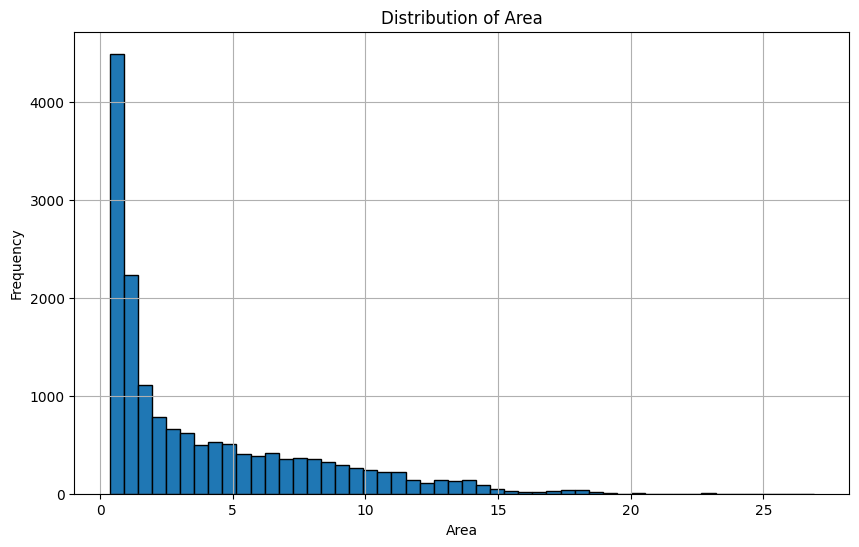

In [35]:
import matplotlib.pyplot as plt

# Plotting the distribution of 'area'
plt.figure(figsize=(10, 6))
plt.hist(filtered_data['area_geo'], bins=50, edgecolor='black')
plt.title('Distribution of Area')
plt.xlabel('Area')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()


In [36]:
# Counting occurrences where latitude or longitude differences are zero
lat_diff_zero_count = np.sum(np.diff(sorted_lat) == 0)
lon_diff_zero_count = np.sum(np.diff(sorted_lon) == 0)

lat_diff_zero_count, lon_diff_zero_count

(0, 0)